# Analisis Sentimen Ulasan Steam: *Lies of P*

**Proyek Analisis Sentimen — Dicoding**

Notebook ini membangun model klasifikasi sentimen (negatif, netral, positif) dari ulasan pemain game *Lies of P* di Steam. Data diperoleh melalui scraping mandiri pada notebook `scraping_lies_of_p.ipynb`.

Alur kerja:
Alur kerja:
1. Persiapan library
2. Memuat dataset
3. Exploratory Data Analysis (EDA) data mentah
4. Pembersihan data (data cleaning)
5. Pelabelan data dengan lexicon VADER
6. EDA setelah pelabelan
7. Pemodelan: tiga skema dengan hyperparameter tuning
8. Analisis kesalahan
9. Perbaikan preprocessing: penandaan negasi (Skema 4)
10. Perbandingan seluruh skema
11. Inferensi
12. Requirements
13. Kesimpulan

## 1. Persiapan Library

### 1.1 Instalasi library tambahan
Dua library berikut belum tersedia secara bawaan di Google Colab:
- `vaderSentiment`: pelabelan sentimen berbasis lexicon (kamus kata berbobot).
- `langdetect`: deteksi bahasa untuk menyaring ulasan yang bukan berbahasa Inggris.

In [1]:
!pip install -q vaderSentiment langdetect

### 1.2 Import library dan pengaturan seed
Library dikelompokkan menjadi empat bagian: pengolahan data dan visualisasi, pelabelan, machine learning klasik (scikit-learn), dan deep learning (TensorFlow/Keras).

Seed acak dikunci (`SEED = 42`) pada Python, NumPy, TensorFlow, dan langdetect agar seluruh hasil, termasuk pembagian data, bobot awal model, dan deteksi bahasa, dapat direproduksi ketika notebook dijalankan ulang.

In [2]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from langdetect import detect, DetectorFactory
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from collections import Counter
from wordcloud import WordCloud
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
import tensorflow as tf
from tensorflow import keras
from collections import Counter
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
DetectorFactory.seed = 0

print('pandas      :', pd.__version__)
print('scikit-learn:', __import__('sklearn').__version__)
print('tensorflow  :', tf.__version__)
print('GPU         :', tf.config.list_physical_devices('GPU'))

pandas      : 2.2.3
scikit-learn: 1.6.1
tensorflow  : 2.21.0
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Memuat Dataset
Dataset dimuat dari file `ulasan_lies_of_p.csv` hasil scraping. File dibaca dengan encoding `utf-8-sig` karena disimpan dengan encoding tersebut agar dapat dibuka dengan rapi di aplikasi spreadsheet.

In [3]:
df = pd.read_csv('ulasan_lies_of_p.csv', encoding='utf-8-sig')

print('Ukuran data (baris, kolom):', df.shape)
print()
df.info()

Ukuran data (baris, kolom): (20098, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20098 entries, 0 to 20097
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   review_id               20098 non-null  int64 
 1   review                  20022 non-null  object
 2   voted_up                20098 non-null  bool  
 3   votes_up                20098 non-null  int64 
 4   playtime_at_review_min  20098 non-null  int64 
 5   timestamp_created       20098 non-null  int64 
 6   language                20098 non-null  object
 7   tanggal                 20098 non-null  object
dtypes: bool(1), int64(4), object(3)
memory usage: 1.1+ MB


**Hasil:** dataset terdiri dari 20.098 ulasan dan 8 kolom. Kolom `review` hanya terisi 20.022 baris, sehingga terdapat 76 ulasan tanpa teks (pengguna hanya memberi rekomendasi tanpa menulis ulasan). Ulasan kosong akan dibuang pada tahap pembersihan.

Keterangan kolom:
| Kolom | Keterangan |
|---|---|
| `review_id` | ID unik ulasan dari Steam |
| `review` | teks ulasan |
| `voted_up` | `True` jika pemain merekomendasikan game |
| `votes_up` | jumlah pengguna lain yang menilai ulasan ini membantu |
| `playtime_at_review_min` | lama bermain (menit) saat ulasan ditulis |
| `timestamp_created` | waktu ulasan dibuat (Unix timestamp) |
| `language` | bahasa ulasan menurut Steam |
| `tanggal` | waktu ulasan dalam format tanggal |

Identitas penulis ulasan (SteamID, nama profil) tidak disimpan demi menjaga privasi.

In [4]:
print('Nilai kosong per kolom:')
print(df.isna().sum())
print()
print('Nama kolom:', list(df.columns))
df.head()

Nilai kosong per kolom:
review_id                  0
review                    76
voted_up                   0
votes_up                   0
playtime_at_review_min     0
timestamp_created          0
language                   0
tanggal                    0
dtype: int64

Nama kolom: ['review_id', 'review', 'voted_up', 'votes_up', 'playtime_at_review_min', 'timestamp_created', 'language', 'tanggal']


,review_id,review,voted_up,votes_up,playtime_at_review_min,timestamp_created,language,tanggal
0,238073815,Meeting boss means: You start attacking -> 1 a...,False,0,461,1792386875,english,2026-10-19 05:14:35
1,238072758,P lied to me so far,True,0,1568,1792384936,english,2026-10-19 04:42:16
2,238072602,"I absolutely recommend this game, with a cavea...",True,0,5124,1792384684,english,2026-10-19 04:38:04
3,238072322,Peak,True,0,1721,1792384213,english,2026-10-19 04:30:13
4,238066578,great game -- really enjoying it so far.,True,0,1412,1792375384,english,2026-10-19 02:03:04


## 3. Exploratory Data Analysis (EDA) Data Mentah
EDA dilakukan pada salinan data (`raw`) agar data asli tidak berubah sebelum tahap pembersihan. Pemeriksaan mencakup ulasan kosong, teks duplikat, panjang ulasan, proporsi rekomendasi, rentang waktu, dan jam bermain.

### 3.1 Ringkasan statistik

In [5]:
raw = df.copy()
raw['review'] = raw['review'].fillna('')
raw['panjang_kata'] = raw['review'].str.split().str.len()
raw['tanggal'] = pd.to_datetime(raw['timestamp_created'], unit='s')
raw['jam_main'] = raw['playtime_at_review_min'] / 60

print('Jumlah ulasan             :', len(raw))
print('Ulasan kosong             :', (raw['review'].str.strip() == '').sum())
print('Teks ulasan duplikat      :', raw['review'].duplicated().sum())
print('Proporsi direkomendasikan :', round(raw['voted_up'].mean(), 3))
print('Rentang tanggal           :', raw['tanggal'].min().date(), 's.d.', raw['tanggal'].max().date())
print()
print('Statistik panjang ulasan (kata):')
print(raw['panjang_kata'].describe().round(1))
print()
print('Ulasan di bawah 3 kata    :', (raw['panjang_kata'] < 3).sum())

Jumlah ulasan             : 20098
Ulasan kosong             : 76
Teks ulasan duplikat      : 2748
Proporsi direkomendasikan : 0.922
Rentang tanggal           : 2024-07-16 s.d. 2026-10-19

Statistik panjang ulasan (kata):
count    20098.0
mean        52.2
std        120.5
min          0.0
25%          3.0
50%         12.0
75%         46.0
max       1537.0
Name: panjang_kata, dtype: float64

Ulasan di bawah 3 kata    : 3648


In [6]:
print('15 teks ulasan yang paling sering muncul:')
raw['review'].str.strip().str.lower().value_counts().head(15)

15 teks ulasan yang paling sering muncul:


,count
review,
lies of peak,485
good,185
peak,138
great game,115
yes,113
good game,113
.,98
10/10,92
,76


**Interpretasi:**
- Panjang ulasan sangat condong ke kanan (*right-skewed*): median 12 kata, sedangkan rata-rata 52,2 kata karena terdapat sebagian kecil ulasan yang sangat panjang (maksimum 1.537 kata).
- Sekitar 25% ulasan berisi 3 kata atau kurang. Sebanyak 3.648 ulasan memiliki kurang dari 3 kata dan terlalu miskin konteks untuk dianalisis.
- Terdapat 2.748 teks duplikat. Teks yang paling sering muncul adalah ulasan singkat bernada pujian seperti "lies of peak" (485 kali), "good", "peak", dan "great game". Jika tidak dihapus, teks yang sama dapat muncul di data latih sekaligus data uji sehingga akurasi model menjadi bias (kebocoran data).
- Banyak ulasan memakai slang komunitas game (misalnya "peak" dan "lies of peak" sebagai pujian) yang belum tentu dikenali kamus sentimen umum. Hal ini menjadi pertimbangan pada tahap pelabelan.
- Sebanyak 92,2% ulasan merekomendasikan game, menandakan data sangat timpang ke arah positif.
- Data mencakup ulasan dari 16 Juli 2024 hingga 19 Oktober 2026 (20.098 ulasan terbaru), sehingga tidak merepresentasikan periode rilis awal game (September 2023).

### 3.2 Visualisasi data mentah
Empat grafik berikut menggambarkan distribusi panjang ulasan, proporsi rekomendasi, jumlah ulasan per bulan, dan jam bermain saat ulasan ditulis. Pada grafik panjang ulasan dan jam bermain, 1% nilai tertinggi dipotong **hanya untuk keperluan tampilan** agar distribusi utama terlihat jelas.

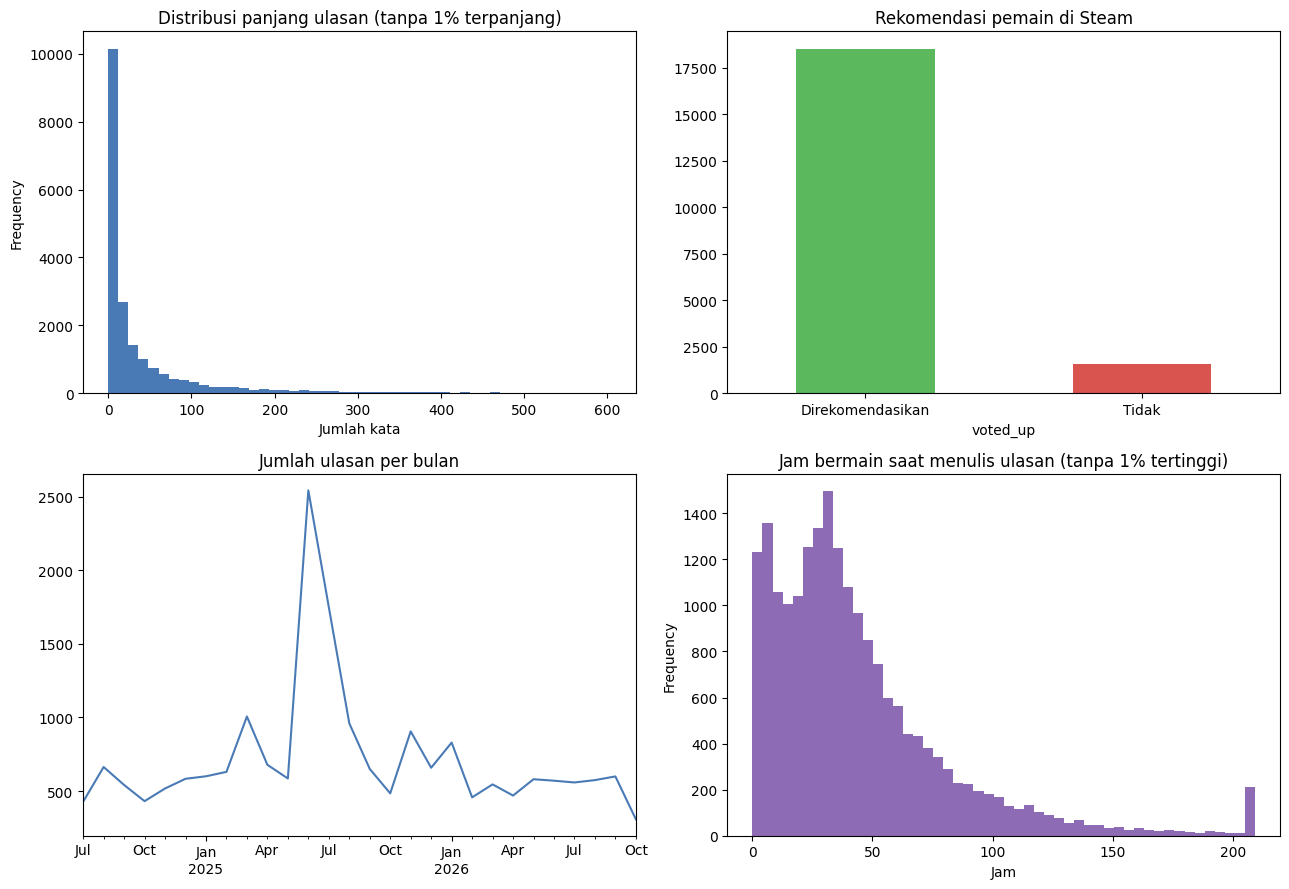

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

batas = raw['panjang_kata'].quantile(0.99)
raw.loc[raw['panjang_kata'] <= batas, 'panjang_kata'].plot.hist(bins=50, ax=ax[0, 0], color='#4a7ab5')
ax[0, 0].set_title('Distribusi panjang ulasan (tanpa 1% terpanjang)')
ax[0, 0].set_xlabel('Jumlah kata')

raw['voted_up'].map({True: 'Direkomendasikan', False: 'Tidak'}).value_counts().plot.bar(
    ax=ax[0, 1], color=['#5cb85c', '#d9534f'])
ax[0, 1].set_title('Rekomendasi pemain di Steam')
ax[0, 1].tick_params(axis='x', rotation=0)

bulanan = raw.set_index('tanggal').resample('MS')['review_id'].count()
bulanan.plot(ax=ax[1, 0], color='#4a7ab5')
ax[1, 0].set_title('Jumlah ulasan per bulan')
ax[1, 0].set_xlabel('')

jam = raw['jam_main'].clip(upper=raw['jam_main'].quantile(0.99))
jam.plot.hist(bins=50, ax=ax[1, 1], color='#8e6bb5')
ax[1, 1].set_title('Jam bermain saat menulis ulasan (tanpa 1% tertinggi)')
ax[1, 1].set_xlabel('Jam')

plt.tight_layout()
plt.show()

In [8]:
raw['kelompok_jam'] = pd.cut(raw['jam_main'], bins=[-0.1, 5, 20, 50, 100, np.inf],
                             labels=['<5 jam', '5-20', '20-50', '50-100', '>100'])
tabel = raw.groupby('kelompok_jam', observed=True)['voted_up'].agg(['count', 'mean'])
tabel.columns = ['jumlah_ulasan', 'proporsi_rekomendasi']
tabel['proporsi_rekomendasi'] = tabel['proporsi_rekomendasi'].round(3)
tabel

,jumlah_ulasan,proporsi_rekomendasi
kelompok_jam,,
<5 jam,1532,0.803
5-20,3912,0.872
20-50,8431,0.937
50-100,4652,0.963
>100,1571,0.962


### Interpretasi EDA data mentah
- Panjang ulasan sangat condong ke kanan (median 12 kata, rata-rata 52 kata, maksimum 1.537 kata). Sekitar 25% ulasan berisi 3 kata atau kurang, sehingga ulasan di bawah 3 kata akan dibuang karena terlalu miskin konteks.
- Terdapat 2.748 teks duplikat, didominasi ulasan template seperti "lies of peak" (485 kali), "good", dan "peak". Duplikat akan dihapus setelah pembersihan agar teks yang sama tidak muncul di data latih sekaligus data uji.
- Data sangat timpang: 92,2% ulasan merekomendasikan game. Label sentimen kemungkinan besar juga didominasi kelas positif, sehingga evaluasi model perlu melihat metrik per kelas, tidak hanya akurasi.
- Jumlah ulasan per bulan relatif stabil (±500–700), kecuali lonjakan sekitar Juni 2025 yang bertepatan dengan puncak jumlah pemain.
- Proporsi rekomendasi meningkat seiring jam bermain (80,3% untuk < 5 jam hingga ±96% untuk > 50 jam). Pola ini bersifat deskriptif, bukan sebab-akibat: pemain yang tidak menyukai game cenderung berhenti lebih awal.
- Data mencakup ulasan Juli 2024 – Oktober 2026, sehingga tidak merepresentasikan periode rilis awal (September 2023).
- Grafik jam bermain memiliki dua puncak: sekitar 0–5 jam dan sekitar 30–40 jam. Puncak kedua kemungkinan mencerminkan pemain yang menulis ulasan setelah menamatkan game. Batang tinggi di ujung kanan (±210 jam) merupakan efek pemotongan tampilan pada persentil 99, bukan data asli.
- Proporsi rekomendasi meningkat seiring lama bermain: 80,3% (< 5 jam), 87,2% (5–20 jam), 93,7% (20–50 jam), dan sekitar 96% (> 50 jam). Pola ini bersifat deskriptif, bukan hubungan sebab-akibat, karena pemain yang tidak menyukai game cenderung berhenti lebih awal.

## 4. Pembersihan Data (Data Cleaning)

### 4.1 Fungsi pembersihan teks
Langkah pembersihan setiap ulasan:
1. Mengubah seluruh huruf menjadi huruf kecil.
2. Menghapus tag format Steam seperti `[h3]`, `[b]`, dan `[/spoiler]`.
3. Menghapus URL.
4. Menghapus angka, tanda baca, dan simbol, menyisakan huruf dan apostrof.
5. Merapikan spasi berlebih.

Dua keputusan penting:
- **Apostrof dipertahankan** agar kata seperti *don't* dan *isn't* tetap utuh, karena VADER mengenalinya sebagai negasi.
- **Stopword tidak dihapus.** Kata seperti *not*, *but*, dan *very* menentukan arah dan kekuatan sentimen; menghapusnya dapat membalik makna kalimat (misalnya "not good" menjadi "good").

In [9]:
def bersihkan_teks(teks):
    teks = str(teks).lower()
    teks = re.sub(r'\[/?[^\]]{1,20}\]', ' ', teks)
    teks = re.sub(r'https?://\S+|www\.\S+', ' ', teks)
    teks = teks.replace('’', "'")
    teks = re.sub(r"[^a-z' ]", ' ', teks)
    teks = re.sub(r"\s'|'\s", ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()
    return teks

contoh = "[h3]Story:[/h3] It's NOT bad, 10/10!!! https://youtu.be/xyz"
print('Sebelum :', contoh)
print('Sesudah :', bersihkan_teks(contoh))

Sebelum : [h3]Story:[/h3] It's NOT bad, 10/10!!! https://youtu.be/xyz
Sesudah : story it's not bad


### 4.2 Tahapan pembersihan data
Data dibersihkan secara bertahap, dan jumlah data dicatat pada setiap tahap:
1. Membuang ulasan kosong.
2. Membersihkan teks, lalu membuang ulasan dengan kurang dari 3 kata.
3. Membuang teks duplikat. Dilakukan setelah pembersihan agar variasi seperti "Lies of Peak." dan "lies of peak" terhitung sama.
4. Membuang ulasan yang bukan berbahasa Inggris, karena VADER hanya dirancang untuk bahasa Inggris.

**Penyaringan bahasa.** Penanda bahasa dari Steam berasal dari pengaturan akun penulis, bukan isi teks, sehingga tetap diperiksa ulang. Uji awal menunjukkan `langdetect` sering keliru pada teks pendek dan slang (misalnya "just an overall great game" terdeteksi sebagai bahasa Norwegia). Karena itu ulasan baru dibuang jika memenuhi tiga syarat sekaligus:
- `langdetect` mendeteksi bahasa selain Inggris,
- rasio kata umum bahasa Inggris (stopword scikit-learn) di bawah 5%, dan
- panjang ulasan minimal 6 kata, agar deteksi cukup andal.

In [10]:
data = df.copy()
catatan = [('Data awal', len(data))]

data = data.dropna(subset=['review'])
data = data[data['review'].str.strip() != '']
catatan.append(('Buang ulasan kosong', len(data)))

data['clean'] = data['review'].apply(bersihkan_teks)
data['jumlah_kata'] = data['clean'].str.split().str.len()
data = data[data['jumlah_kata'] >= 3]
catatan.append(('Buang ulasan < 3 kata', len(data)))

data = data.drop_duplicates(subset='clean')
catatan.append(('Buang teks duplikat', len(data)))

def deteksi_bahasa(teks):
    try:
        return detect(teks)
    except Exception:
        return 'gagal'

def rasio_kata_umum_inggris(teks):
    kata = teks.split()
    return sum(k in ENGLISH_STOP_WORDS for k in kata) / len(kata)

data['bahasa'] = data['clean'].apply(deteksi_bahasa)
data['rasio_en'] = data['clean'].apply(rasio_kata_umum_inggris)

bukan_inggris = (data['bahasa'] != 'en') & (data['rasio_en'] < 0.05) & (data['jumlah_kata'] >= 6)
diselamatkan = (data['bahasa'] != 'en') & ~bukan_inggris

print('Langdetect bilang bukan Inggris :', (data['bahasa'] != 'en').sum())
print('  -> diselamatkan (banyak kata Inggris) :', diselamatkan.sum())
print('  -> dibuang                            :', bukan_inggris.sum())

print('\nContoh yang DIBUANG:')
print(data.loc[bukan_inggris, ['clean', 'bahasa', 'rasio_en']].sample(10, random_state=SEED).to_string())
print('\nContoh yang DISELAMATKAN:')
print(data.loc[diselamatkan, ['clean', 'bahasa', 'rasio_en']].sample(10, random_state=SEED).to_string())

data = data[~bukan_inggris].reset_index(drop=True)
catatan.append(('Buang ulasan bukan bahasa Inggris', len(data)))

print()
pd.DataFrame(catatan, columns=['Tahap', 'Jumlah data'])

Langdetect bilang bukan Inggris : 1304
  -> diselamatkan (banyak kata Inggris) : 1244
  -> dibuang                            : 60

Contoh yang DIBUANG:
                                                                                                                                                                                                                                                                                         clean bahasa  rasio_en
868                                                                                                                             m na koydu umun nameless puppet yorma ya neyse dlc indirim bekliyoruz oyun g zel biraz daha b l m ve d man e itlili i olsayd souls oyunlar n n seviyesine kard     tr  0.030303
2908                                                                                                                                                                                                                                          m

,Tahap,Jumlah data
0,Data awal,20098
1,Buang ulasan kosong,20022
2,Buang ulasan < 3 kata,16279
3,Buang teks duplikat,15107
4,Buang ulasan bukan bahasa Inggris,15047


**Hasil pembersihan:**

| Tahap | Jumlah data | Dibuang |
|---|---|---|
| Data awal | 20.098 | – |
| Buang ulasan kosong | 20.022 | 76 |
| Buang ulasan < 3 kata | 16.279 | 3.743 |
| Buang teks duplikat | 15.107 | 1.172 |
| Buang ulasan bukan bahasa Inggris | 15.047 | 60 |

Dari 1.304 ulasan yang dideteksi `langdetect` sebagai bukan bahasa Inggris, 1.244 dipertahankan karena terbukti mengandung kata-kata umum bahasa Inggris atau terlalu pendek untuk dinilai, dan hanya 60 yang dibuang. Pemeriksaan sampel menunjukkan ulasan yang dibuang didominasi bahasa Turki, Portugis, Spanyol, dan Swedia. Sebagai perbandingan, penggunaan `langdetect` saja membuang lebih dari 600 ulasan yang sebagian besar sebenarnya berbahasa Inggris.

Dataset akhir berjumlah **15.047 ulasan**, memenuhi target minimal 10.000 sampel.

## 5. Pelabelan Data dengan Lexicon VADER

### 5.1 Penyesuaian lexicon dengan bahasa komunitas game
VADER (*Valence Aware Dictionary and sEntiment Reasoner*) memberi skor sentimen berdasarkan kamus kata berbobot (skala −4 sampai +4), serta aturan untuk negasi (*not*), penguat (*very*), dan kontras (*but*). Kamus ini dirancang untuk bahasa umum, sehingga kurang tepat untuk ulasan game:
1. Slang pujian komunitas game (*peak*, *goated*, *banger*) tidak dikenali sehingga dianggap netral.
2. Kata yang wajar dalam genre soulslike (*died*, *kill*, *hard*, *brutal*) dianggap negatif, padahal umumnya hanya menggambarkan permainan.
3. Kata *lies* pada judul game "Lies of P" dianggap negatif.

Karena itu lexicon VADER disesuaikan: slang pujian diberi skor positif, slang keluhan (*mid*, *janky*, *buggy*) diberi skor negatif, dan kata-kata khas genre diberi skor 0 (netral). Efek penyesuaian dibuktikan dengan membandingkan skor beberapa kalimat uji sebelum dan sesudah penyesuaian.

In [11]:
analyzer = SentimentIntensityAnalyzer()

kalimat_uji = [
    'lies of peak',
    'this game is goated',
    'absolute banger',
    'i died so many times but the bosses are amazing',
    'lies of p is a masterpiece',
    'brutal but fair boss fights',
    'mid game honestly',
    'janky and buggy port keeps stuttering',
]
skor_sebelum = [analyzer.polarity_scores(k)['compound'] for k in kalimat_uji]

slang_game = {
    # slang pujian pemain
    'peak': 2.5, 'goated': 3.0, 'banger': 2.5, 'kino': 2.0, 'cinema': 2.0, 'based': 1.5,
    # slang keluhan pemain
    'mid': -1.5, 'janky': -1.5, 'jank': -1.5, 'buggy': -2.0, 'unplayable': -3.0,
    'stuttering': -1.5, 'stutters': -1.5, 'stutter': -1.5,
    # kata yang di game soulslike bersifat netral
    'lies': 0.0, 'lie': 0.0, 'lied': 0.0,
    'die': 0.0, 'died': 0.0, 'dying': 0.0, 'death': 0.0, 'dead': 0.0,
    'kill': 0.0, 'killed': 0.0, 'killing': 0.0,
    'hard': 0.0, 'difficult': 0.0, 'brutal': 0.0, 'punishing': 0.0,
    'fight': 0.0, 'fights': 0.0, 'fighting': 0.0, 'attack': 0.0, 'attacks': 0.0,
    'enemy': 0.0, 'enemies': 0.0, 'war': 0.0,
}
analyzer.lexicon.update(slang_game)

skor_sesudah = [analyzer.polarity_scores(k)['compound'] for k in kalimat_uji]
pd.DataFrame({'kalimat': kalimat_uji, 'sebelum': skor_sebelum, 'sesudah': skor_sesudah})

,kalimat,sebelum,sesudah
0,lies of peak,-0.4215,0.5423
1,this game is goated,0.0000,0.6124
2,absolute banger,0.0000,0.5423
3,i died so many times but the bosses are amazing,0.5994,0.7351
4,lies of p is a masterpiece,0.3182,0.6249
5,brutal but fair boss fights,-0.4854,0.4497
6,mid game honestly,0.4588,0.1280
7,janky and buggy port keeps stuttering,-0.3182,-0.7906


**Hasil:** penyesuaian bekerja sesuai tujuan. Contohnya, "lies of peak" yang semula bernilai −0,42 (negatif) menjadi +0,54 (positif), dan "brutal but fair boss fights" dari −0,49 menjadi +0,45. Temuan terpenting: tanpa penyesuaian, setiap ulasan yang menyebut judul "Lies of P" mendapat bias negatif.

Penyesuaian ini tidak sempurna. Misalnya, "mid game honestly" tetap bernilai positif (+0,13) karena kata *honestly* berbobot positif. Daftar kata yang disesuaikan merupakan keputusan peneliti berdasarkan pengetahuan bahasa komunitas game, bukan daftar baku.

### 5.2 Pemberian label
Label ditentukan dari skor *compound* VADER dengan ambang standar dari penulis VADER:
| Skor compound | Label |
|---|---|
| ≥ 0,05 | positif |
| ≤ −0,05 | negatif |
| di antaranya | netral |

Pelabelan dilakukan pada teks yang sudah dibersihkan (kolom `clean`), yaitu teks yang sama dengan input model, agar label konsisten dengan data yang dipelajari model.

In [12]:
def label_vader(skor):
    if skor >= 0.05:
        return 'positif'
    if skor <= -0.05:
        return 'negatif'
    return 'netral'

data['compound'] = data['clean'].apply(lambda t: analyzer.polarity_scores(t)['compound'])
data['label'] = data['compound'].apply(label_vader)

print('Distribusi label:')
print(data['label'].value_counts())
print()
print(data['label'].value_counts(normalize=True).round(3))
print()
print('Label VADER vs rekomendasi pemain (proporsi per baris):')
pd.crosstab(data['voted_up'], data['label'], normalize='index').round(3)

Distribusi label:
label
positif    12056
negatif     1627
netral      1364
Name: count, dtype: int64

label
positif    0.801
negatif    0.108
netral     0.091
Name: proportion, dtype: float64

Label VADER vs rekomendasi pemain (proporsi per baris):


label,negatif,netral,positif
voted_up,,,
False,0.484,0.081,0.435
True,0.069,0.092,0.839


**Hasil pelabelan:**
| Label | Jumlah | Proporsi |
|---|---|---|
| Positif | 12.056 | 80,1% |
| Negatif | 1.627 | 10,8% |
| Netral | 1.364 | 9,1% |

Data sangat timpang ke kelas positif. Model yang selalu menebak "positif" sudah mencapai akurasi 80,1%, sehingga evaluasi model juga harus memperhatikan precision, recall, dan F1-score per kelas, khususnya kelas negatif dan netral.

**Pemeriksaan kewajaran label:** label negatif muncul pada 48,4% ulasan yang tidak merekomendasikan game, dibandingkan hanya 6,9% pada ulasan yang merekomendasikan. Arah ini sesuai harapan sehingga label dinilai masuk akal. Namun 43,5% ulasan yang tidak merekomendasikan justru berlabel positif. Hal ini mencerminkan keterbatasan pelabelan berbasis lexicon terhadap ulasan bercampur (memuji sekaligus mengkritik) dan sarkasme. Label VADER mengukur nada teks, sedangkan rekomendasi Steam mengukur keputusan pemain; keduanya tidak selalu sejalan.

## 6. EDA Setelah Pelabelan
Bagian ini memeriksa karakteristik tiap kelas sentimen: sebaran skor VADER, panjang ulasan, kata yang paling sering muncul, word cloud, serta contoh ulasan. Stopword dan kata yang muncul di semua kelas (*game*, *lies*, *p*) disaring **hanya untuk visualisasi**; teks yang digunakan model tetap utuh.

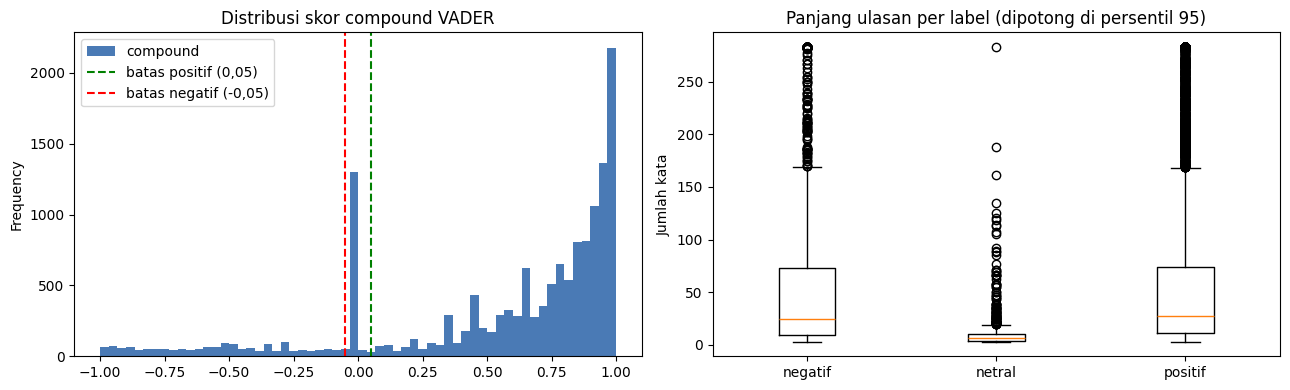

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negatif,1627.0,75.0,148.2,3.0,9.0,24.0,73.0,1492.0
netral,1364.0,10.2,23.6,3.0,4.0,6.0,10.0,701.0
positif,12056.0,73.6,137.6,3.0,11.0,27.0,74.0,1523.0


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

data['compound'].plot.hist(bins=60, ax=ax[0], color='#4a7ab5')
ax[0].axvline(0.05, color='green', ls='--', label='batas positif (0,05)')
ax[0].axvline(-0.05, color='red', ls='--', label='batas negatif (-0,05)')
ax[0].set_title('Distribusi skor compound VADER')
ax[0].legend()

urutan = ['negatif', 'netral', 'positif']
batas95 = data['jumlah_kata'].quantile(0.95)
data_box = [data.loc[data['label'] == k, 'jumlah_kata'].clip(upper=batas95) for k in urutan]
ax[1].boxplot(data_box)
ax[1].set_xticks([1, 2, 3], urutan)
ax[1].set_title('Panjang ulasan per label (dipotong di persentil 95)')
ax[1].set_ylabel('Jumlah kata')

plt.tight_layout()
plt.show()

data.groupby('label')['jumlah_kata'].describe().round(1)

**Interpretasi:**
- Skor compound kelas positif menumpuk mendekati +1, menunjukkan sentimen positif yang tegas. Ulasan negatif tersebar merata antara −1 dan −0,05.
- Terdapat lonjakan tepat pada skor 0 (sekitar 1.300 ulasan). Hampir seluruh kelas netral memiliki skor tepat 0, artinya VADER tidak menemukan kata bersentimen pada ulasan tersebut.
- Ulasan netral jauh lebih pendek (median 6 kata) dibanding ulasan negatif (median 24 kata) dan positif (median 27 kata).

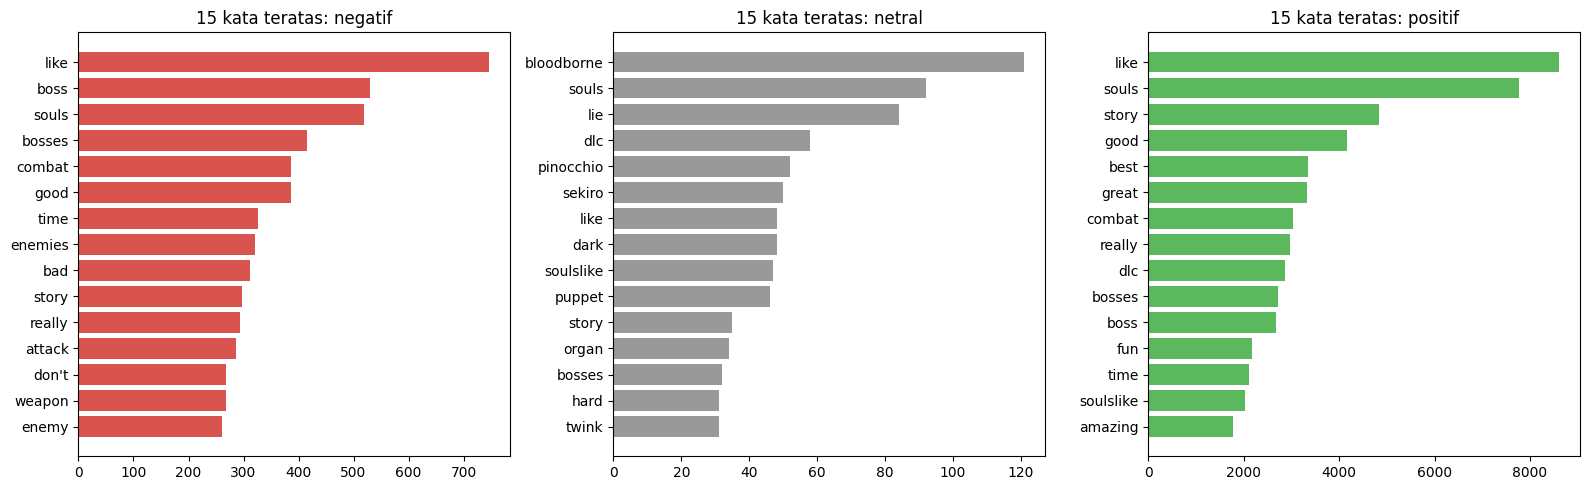

In [14]:
STOP_VIS = set(ENGLISH_STOP_WORDS) | {'game', 'games', 'lies', 'p', 'play', 'played', 'playing',
                                      'just', 've', 'll', 'don', 'didn', 'doesn', "it's", "i'm", "i've"}

def kata_teratas(teks_series, n=15):
    hitung = Counter(w for t in teks_series for w in t.split() if w not in STOP_VIS and len(w) > 2)
    return pd.DataFrame(hitung.most_common(n), columns=['kata', 'frekuensi'])

warna = {'negatif': '#d9534f', 'netral': '#999999', 'positif': '#5cb85c'}
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for i, k in enumerate(urutan):
    top = kata_teratas(data.loc[data['label'] == k, 'clean'])
    ax[i].barh(top['kata'][::-1], top['frekuensi'][::-1], color=warna[k])
    ax[i].set_title(f'15 kata teratas: {k}')
plt.tight_layout()
plt.show()

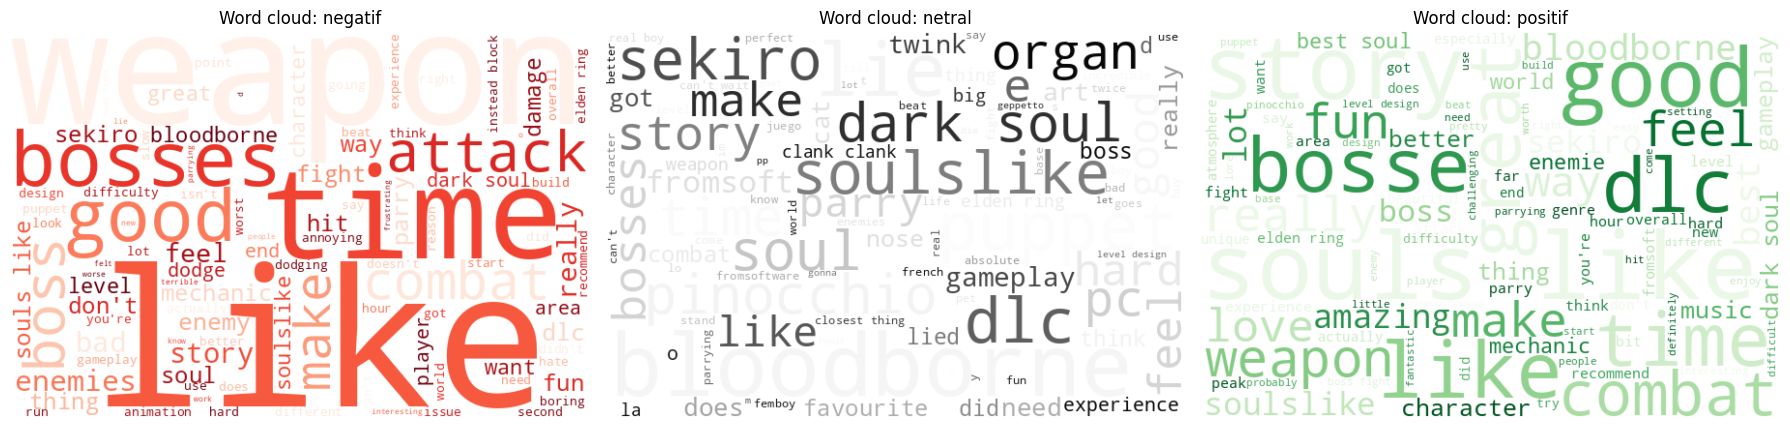

In [15]:
peta_warna = {'negatif': 'Reds', 'netral': 'Greys', 'positif': 'Greens'}
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, k in enumerate(urutan):
    teks = ' '.join(data.loc[data['label'] == k, 'clean'])
    wc = WordCloud(width=600, height=400, background_color='white', stopwords=STOP_VIS,
                   colormap=peta_warna[k], max_words=100, random_state=SEED).generate(teks)
    ax[i].imshow(wc, interpolation='bilinear')
    ax[i].set_title(f'Word cloud: {k}')
    ax[i].axis('off')
plt.tight_layout()
plt.show()

**Interpretasi:**
- **Positif:** didominasi kata penilaian seperti *good*, *best*, *great*, *amazing*, *fun*, serta aspek game yang dipuji seperti *story*, *combat*, *bosses*, dan *dlc*.
- **Negatif:** didominasi aspek permainan (*boss*, *combat*, *enemies*, *attack*, *weapon*) serta kata *bad*, *don't*, dan *annoying*. Kritik umumnya ditujukan pada desain pertarungan. Kata *good* juga sering muncul karena banyak ulasan negatif bersifat campuran ("good, but...") atau berisi negasi ("not good").
- **Netral:** didominasi perbandingan dengan game lain (*bloodborne*, *sekiro*, *dark souls*) dan meme komunitas (*organ*, *twink*, *puppet*), yaitu teks yang tidak mengandung kata bersentimen.

In [16]:
pd.set_option('display.max_colwidth', 200)
for k in urutan:
    print(f'=== Contoh ulasan {k} ===')
    contoh_k = data.loc[(data['label'] == k) & (data['jumlah_kata'].between(8, 40)), ['clean', 'compound']]
    print(contoh_k.sample(5, random_state=SEED).to_string(index=False))
    print()

=== Contoh ulasan negatif ===
                                                                                                                                                                                 clean  compound
                                                                                               the industrial revolution and it's consequences have been a disaster for the human race   -0.6249
love the parrying system especially making an enemies weapon break from parrying them so much only thing is the rolling dodging isn't the best but it could just have a different feel   -0.0650
                                                 somehow both an uplifting and depressing game all in one i expected bloodborne in france and instead got resident evil souls in paris   -0.7906
                                                                                            combat is slow and floaty bosses spam billion moves before you can attack once snooze fest   -0.5994
     

**Evaluasi contoh label:**
- Contoh positif seluruhnya sesuai.
- Pada kelas negatif terdapat kesalahan akibat lelucon dan sarkasme, misalnya *copypasta* "the industrial revolution and its consequences..." dan pujian bergaya sarkas "id say this game was a waste of time but that'd be a lie".
- Pada kelas netral terdapat ulasan positif yang tidak terdeteksi karena memakai ejaan Inggris-Britania atau idiom, misalnya "possibly my favourite game of the past years ... take the cake".

**Keterbatasan:** pelabelan berbasis lexicon tidak mampu menangkap sarkasme, meme, dan idiom. Penyesuaian kamus tidak dilanjutkan karena kesalahan tersebut bersifat kontekstual dan tidak dapat diselesaikan dengan menambah kata. Dengan demikian, akurasi model pada bagian berikutnya mengukur kemampuan model **mereplikasi label VADER**, bukan sentimen sebenarnya menurut manusia.

## 7. Pemodelan

### 7.1 Persiapan
Fitur (`X`) adalah teks bersih dan target (`y`) adalah label VADER. Fungsi `evaluasi()` digunakan oleh ketiga skema untuk melaporkan akurasi training dan testing, precision, recall, dan F1-score per kelas, serta confusion matrix.

Aturan hyperparameter tuning: parameter dipilih melalui 5-fold stratified cross-validation pada **data latih saja**. Data uji hanya dipakai satu kali di akhir untuk model terbaik, agar akurasi testing tidak bias.

In [17]:
X = data['clean'].values
y = data['label'].values
KELAS = ['negatif', 'netral', 'positif']
hasil = []
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluasi(nama, y_train, pred_train, y_test, pred_test):
    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)
    print(nama)
    print(f'  Akurasi training : {acc_train:.4f}')
    print(f'  Akurasi testing  : {acc_test:.4f}\n')
    print(classification_report(y_test, pred_test, labels=KELAS, digits=4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, labels=KELAS, cmap='Blues')
    plt.title(nama)
    plt.show()
    hasil.append({'Skema': nama, 'Akurasi train': acc_train, 'Akurasi test': acc_test})

def ringkas_grid(grid, kolom_param, n=8):
    res = pd.DataFrame(grid.cv_results_)
    kolom = ['param_' + k for k in kolom_param] + ['mean_train_score', 'mean_test_score', 'rank_test_score']
    out = res[kolom].sort_values('rank_test_score').head(n).copy()
    out.columns = [c.replace('param_', '') for c in out.columns]
    return out.round(4)

print('Jumlah data:', len(X))

Jumlah data: 15047


### 7.2 Skema 1 — LinearSVC + TF-IDF, pembagian data 80/20
TF-IDF dan LinearSVC digabung dalam satu `Pipeline`, sehingga pada setiap fold cross-validation TF-IDF hanya mempelajari kosakata dari bagian latih (tidak ada kebocoran data).

Sebagai pembanding disertakan baseline `DummyClassifier` yang selalu menebak kelas terbanyak (positif).

Ruang pencarian hyperparameter (16 kombinasi × 5 fold):
| Parameter | Nilai | Keterangan |
|---|---|---|
| `ngram_range` | (1,1), (1,2) | unigram saja, atau unigram + bigram |
| `min_df` | 1, 2 | frekuensi dokumen minimum sebuah kata |
| `C` | 0,1; 0,5; 1; 2 | kekuatan regularisasi SVM |

In [18]:
X_tr1, X_te1, y_tr1, y_te1 = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Data latih:', len(X_tr1), '| Data uji:', len(X_te1))

baseline = DummyClassifier(strategy='most_frequent').fit(X_tr1, y_tr1)
print(f'Akurasi baseline (selalu menebak "positif"): {baseline.score(X_te1, y_te1):.4f}\n')

pipe1 = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=50000, sublinear_tf=True)),
    ('svm', LinearSVC(random_state=SEED, max_iter=5000)),
])
param1 = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'svm__C': [0.1, 0.5, 1, 2],
}
grid1 = GridSearchCV(pipe1, param1, cv=cv5, scoring='accuracy', n_jobs=-1, return_train_score=True)
grid1.fit(X_tr1, y_tr1)

print('Parameter terbaik :', grid1.best_params_)
print(f'Akurasi CV terbaik: {grid1.best_score_:.4f}')
ringkas_grid(grid1, ['tfidf__ngram_range', 'tfidf__min_df', 'svm__C'])

Data latih: 12037 | Data uji: 3010
Akurasi baseline (selalu menebak "positif"): 0.8013

Parameter terbaik : {'svm__C': 1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Akurasi CV terbaik: 0.8915


,tfidf__ngram_range,tfidf__min_df,svm__C,mean_train_score,mean_test_score,rank_test_score
10,"(1, 1)",2,1.0,0.9851,0.8915,1
6,"(1, 1)",2,0.5,0.9709,0.8913,2
4,"(1, 1)",1,0.5,0.9750,0.8907,3
8,"(1, 1)",1,1.0,0.9883,0.8906,4
12,"(1, 1)",1,2.0,0.9935,0.8885,5
13,"(1, 2)",1,2.0,0.9994,0.8883,6
15,"(1, 2)",2,2.0,0.9994,0.8881,7
14,"(1, 1)",2,2.0,0.9917,0.8874,8


**Hasil tuning:** kombinasi terbaik adalah unigram, `min_df=2`, dan `C=1` dengan akurasi cross-validation 89,15%. Seluruh kombinasi teratas memakai unigram. Penambahan bigram menaikkan akurasi training hingga 99,9% tetapi menurunkan akurasi validasi, menandakan overfitting pada pasangan kata yang jarang muncul.

Skema 1: LinearSVC + TF-IDF (80/20)
  Akurasi training : 0.9835
  Akurasi testing  : 0.8970

              precision    recall  f1-score   support

     negatif     0.7229    0.5538    0.6272       325
      netral     0.7273    0.7326    0.7299       273
     positif     0.9332    0.9619    0.9473      2412

    accuracy                         0.8970      3010
   macro avg     0.7945    0.7494    0.7681      3010
weighted avg     0.8918    0.8970    0.8930      3010



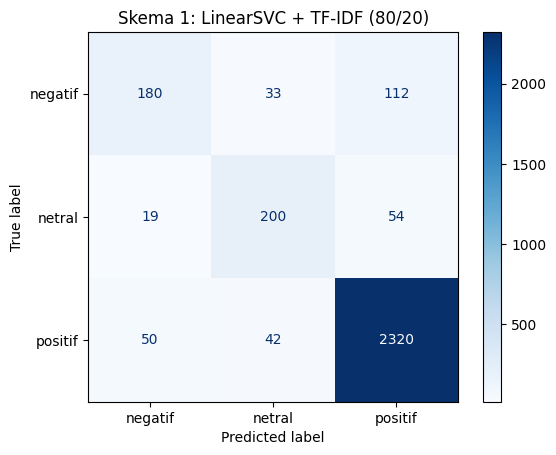

Model tersimpan: model_skema1_svm_tfidf.joblib


In [19]:
skema1 = grid1.best_estimator_
evaluasi('Skema 1: LinearSVC + TF-IDF (80/20)',
         y_tr1, skema1.predict(X_tr1), y_te1, skema1.predict(X_te1))

joblib.dump(skema1, 'model_skema1_svm_tfidf.joblib')
print('Model tersimpan: model_skema1_svm_tfidf.joblib')

**Hasil Skema 1:**
| Ukuran | Nilai |
|---|---|
| Akurasi baseline | 80,13% |
| Akurasi cross-validation | 89,15% |
| Akurasi training | 98,35% |
| Akurasi testing | **89,70%** |

- Akurasi testing memenuhi syarat minimal 85% dan hampir sama dengan akurasi cross-validation, menandakan hasil yang stabil.
- Selisih akurasi training dan testing (±8,7 poin) menunjukkan overfitting moderat.
- Kelas positif diprediksi sangat baik (F1 0,95) dan kelas netral cukup baik (F1 0,73). Kelas negatif paling sulit (recall 55%): 112 dari 325 ulasan negatif diprediksi positif, karena banyak ulasan negatif bersifat campuran dan mengandung kata positif.
- TF-IDF tidak memperhatikan urutan kata, sehingga model linear tidak dapat sepenuhnya meniru aturan VADER yang bergantung pada urutan (negasi, kontras "but", penguat).

Model disimpan dengan `joblib` sebagai `model_skema1_svm_tfidf.joblib`.

### 7.3 Skema 2 — Logistic Regression + TF-IDF, pembagian data 70/30
Skema ini berbeda dari Skema 1 pada dua komponen: algoritma (Logistic Regression) dan pembagian data (70/30). Logistic Regression memodelkan probabilitas tiap kelas, sedangkan SVM mencari batas pemisah dengan margin terlebar. Berdasarkan hasil Skema 1, `min_df=2` langsung digunakan.

Ruang pencarian hyperparameter (8 kombinasi × 5 fold):
| Parameter | Nilai |
|---|---|
| `ngram_range` | (1,1), (1,2) |
| `C` | 1, 5, 10, 20 |

In [20]:
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
print('Data latih:', len(X_tr2), '| Data uji:', len(X_te2))

pipe2 = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=50000, sublinear_tf=True, min_df=2)),
    ('logreg', LogisticRegression(max_iter=3000)),
])
param2 = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'logreg__C': [1, 5, 10, 20],
}
grid2 = GridSearchCV(pipe2, param2, cv=cv5, scoring='accuracy', n_jobs=-1, return_train_score=True)
grid2.fit(X_tr2, y_tr2)

print('Parameter terbaik :', grid2.best_params_)
print(f'Akurasi CV terbaik: {grid2.best_score_:.4f}')
ringkas_grid(grid2, ['tfidf__ngram_range', 'logreg__C'])

Data latih: 10532 | Data uji: 4515
Parameter terbaik : {'logreg__C': 5, 'tfidf__ngram_range': (1, 1)}
Akurasi CV terbaik: 0.8921


,tfidf__ngram_range,logreg__C,mean_train_score,mean_test_score,rank_test_score
2,"(1, 1)",5,0.9823,0.8921,1
4,"(1, 1)",10,0.9909,0.8920,2
6,"(1, 1)",20,0.9949,0.8897,3
7,"(1, 2)",20,0.9995,0.8847,4
5,"(1, 2)",10,0.9991,0.8813,5
3,"(1, 2)",5,0.9961,0.8785,6
0,"(1, 1)",1,0.9316,0.8770,7
1,"(1, 2)",1,0.9246,0.8533,8


Skema 2: LogReg + TF-IDF (70/30)
  Akurasi training : 0.9804
  Akurasi testing  : 0.8950

              precision    recall  f1-score   support

     negatif     0.6973    0.5287    0.6014       488
      netral     0.7500    0.7042    0.7264       409
     positif     0.9293    0.9660    0.9473      3618

    accuracy                         0.8950      4515
   macro avg     0.7922    0.7329    0.7583      4515
weighted avg     0.8880    0.8950    0.8899      4515



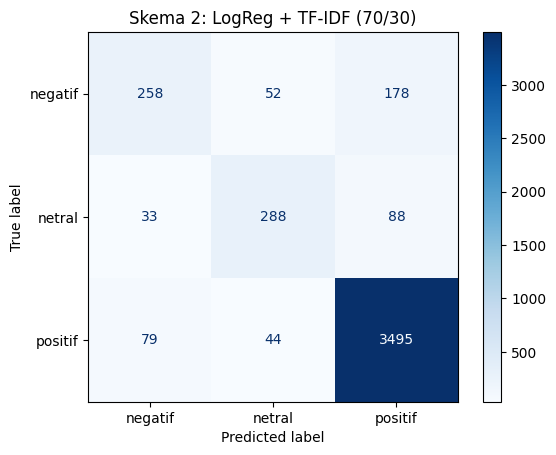

Model tersimpan: model_skema2_logreg_tfidf.joblib


In [21]:
skema2 = grid2.best_estimator_
evaluasi('Skema 2: LogReg + TF-IDF (70/30)',
         y_tr2, skema2.predict(X_tr2), y_te2, skema2.predict(X_te2))

joblib.dump(skema2, 'model_skema2_logreg_tfidf.joblib')
print('Model tersimpan: model_skema2_logreg_tfidf.joblib')

**Hasil Skema 2:** kombinasi terbaik adalah unigram dan `C=5` (akurasi cross-validation 89,21%). Akurasi training 98,04% dan akurasi testing **89,50%**, memenuhi syarat minimal 85%.

Hasilnya hampir identik dengan Skema 1: bigram kembali memicu overfitting, kelas negatif tetap paling sulit (recall 52,9%), dan kelas netral cukup baik (F1 0,73). Dua algoritma linear dengan pembagian data berbeda sama-sama mencapai batas sekitar 89–90%. Hal ini mengindikasikan bahwa keterbatasan berasal dari representasi TF-IDF yang mengabaikan urutan kata, bukan dari pilihan algoritma.

Model disimpan sebagai `model_skema2_logreg_tfidf.joblib`.

### 7.4 Skema 3 — BiLSTM + Word Embedding, pembagian data 80/20 (deep learning)
Skema ini berbeda dari Skema 1 pada algoritma (BiLSTM) dan metode ekstraksi fitur (word embedding yang dipelajari). Pembagian data dan seed sama dengan Skema 1, sehingga data ujinya identik dan perbandingan kedua skema adil.

Data latih dibagi lagi menjadi 90% untuk pelatihan dan 10% untuk validasi. Validasi digunakan untuk memilih konfigurasi dan untuk early stopping; data uji tidak digunakan selama pelatihan.

Teks diubah menjadi urutan indeks kata menggunakan `TextVectorization` (20.000 kata tersering, panjang 300 token). Panjang 300 dipilih agar 95,4% ulasan termuat utuh, karena label VADER ditentukan oleh keseluruhan teks.

In [22]:
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_fit3, X_val3, y_fit3, y_val3 = train_test_split(X_tr3, y_tr3, test_size=0.1, stratify=y_tr3, random_state=SEED)

label2id = {k: i for i, k in enumerate(KELAS)}
id2label = {i: k for k, i in label2id.items()}
ke_id = lambda arr: np.array([label2id[v] for v in arr])

MAX_TOKENS = 20000
MAX_LEN = 300
panjang = pd.Series([len(t.split()) for t in X_tr3])
print(f'Ulasan yang muat utuh dalam {MAX_LEN} kata: {(panjang <= MAX_LEN).mean():.1%}')

vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN,
                                      standardize=None)
vectorizer.adapt(X_fit3)

seq_fit = vectorizer(np.array(X_fit3)).numpy()
seq_val = vectorizer(np.array(X_val3)).numpy()
seq_tr = vectorizer(np.array(X_tr3)).numpy()
seq_te = vectorizer(np.array(X_te3)).numpy()
print('Latih:', seq_fit.shape, '| Validasi:', seq_val.shape, '| Uji:', seq_te.shape)
print('Ukuran kosakata:', len(vectorizer.get_vocabulary()))

Ulasan yang muat utuh dalam 300 kata: 95.4%
Latih: (10833, 300) | Validasi: (1204, 300) | Uji: (3010, 300)
Ukuran kosakata: 18884


#### Hyperparameter tuning BiLSTM
Empat konfigurasi dibandingkan berdasarkan akurasi validasi:
| No | Arsitektur | Keterangan |
|---|---|---|
| 1 | dasar, dropout 0,3 | satu lapis BiLSTM (patokan) |
| 2 | dasar, dropout 0,5 | regularisasi lebih kuat |
| 3 | stacked | dua lapis BiLSTM bertumpuk |
| 4 | pooling | rata-rata keluaran BiLSTM di semua posisi kata |

Seluruh konfigurasi memakai embedding 128 dimensi, 64 unit LSTM, learning rate 0,001, dan early stopping (patience 3).

In [23]:
def bangun_model(arsitektur, emb_dim, lstm_units, dropout, lr):
    inp = layers.Input(shape=(MAX_LEN,))
    x = layers.Embedding(MAX_TOKENS, emb_dim, mask_zero=True)(inp)
    if arsitektur == 'stacked':
        x = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True))(x)
        x = layers.Bidirectional(layers.LSTM(lstm_units))(x)
    elif arsitektur == 'pooling':
        x = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True))(x)
        x = layers.GlobalAveragePooling1D()(x)
    else:
        x = layers.Bidirectional(layers.LSTM(lstm_units))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(len(KELAS), activation='softmax')(x)

    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

konfigurasi = [
    {'arsitektur': 'dasar',   'emb_dim': 128, 'lstm_units': 64, 'dropout': 0.3, 'lr': 1e-3},
    {'arsitektur': 'dasar',   'emb_dim': 128, 'lstm_units': 64, 'dropout': 0.5, 'lr': 1e-3},
    {'arsitektur': 'stacked', 'emb_dim': 128, 'lstm_units': 64, 'dropout': 0.3, 'lr': 1e-3},
    {'arsitektur': 'pooling', 'emb_dim': 128, 'lstm_units': 64, 'dropout': 0.3, 'lr': 1e-3},
]

hasil_tuning, model_terbaik, history_terbaik, val_terbaik = [], None, None, -1
for i, cfg in enumerate(konfigurasi, 1):
    keras.utils.set_random_seed(SEED)
    m = bangun_model(**cfg)
    es = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)
    h = m.fit(seq_fit, ke_id(y_fit3), validation_data=(seq_val, ke_id(y_val3)),
              epochs=15, batch_size=64, callbacks=[es], verbose=0)
    terbaik = int(np.argmax(h.history['val_accuracy']))
    hasil_tuning.append({**cfg,
                         'epoch_terbaik': terbaik + 1,
                         'akurasi_train': round(h.history['accuracy'][terbaik], 4),
                         'akurasi_validasi': round(h.history['val_accuracy'][terbaik], 4)})
    print(f"Konfigurasi {i} ({cfg['arsitektur']}, dropout {cfg['dropout']}): "
          f"val_accuracy {h.history['val_accuracy'][terbaik]:.4f} di epoch {terbaik + 1}")
    if h.history['val_accuracy'][terbaik] > val_terbaik:
        model_terbaik, history_terbaik, val_terbaik = m, h, h.history['val_accuracy'][terbaik]

pd.DataFrame(hasil_tuning).sort_values('akurasi_validasi', ascending=False)

Konfigurasi 1 (dasar, dropout 0.3): val_accuracy 0.8904 di epoch 3
Konfigurasi 2 (dasar, dropout 0.5): val_accuracy 0.8837 di epoch 3
Konfigurasi 3 (stacked, dropout 0.3): val_accuracy 0.8904 di epoch 4
Konfigurasi 4 (pooling, dropout 0.3): val_accuracy 0.8854 di epoch 4


,arsitektur,emb_dim,lstm_units,dropout,lr,epoch_terbaik,akurasi_train,akurasi_validasi
0,dasar,128,64,0.3,0.001,3,0.9556,0.8904
2,stacked,128,64,0.3,0.001,4,0.9663,0.8904
3,pooling,128,64,0.3,0.001,4,0.9748,0.8854
1,dasar,128,64,0.5,0.001,3,0.9426,0.8837


**Hasil tuning:** konfigurasi terbaik adalah BiLSTM bertumpuk (stacked) dengan akurasi validasi 89%. Keempat konfigurasi berada pada rentang 88,5–89% dan mencapai akurasi validasi terbaik pada epoch ke-3 atau ke-4, setelah itu model mulai overfitting.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 300, 128)  │  2,560,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 300)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,001,803 (30.52 MB)

 Trainable params: 2,667,267 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,334,536 (20.35 MB)

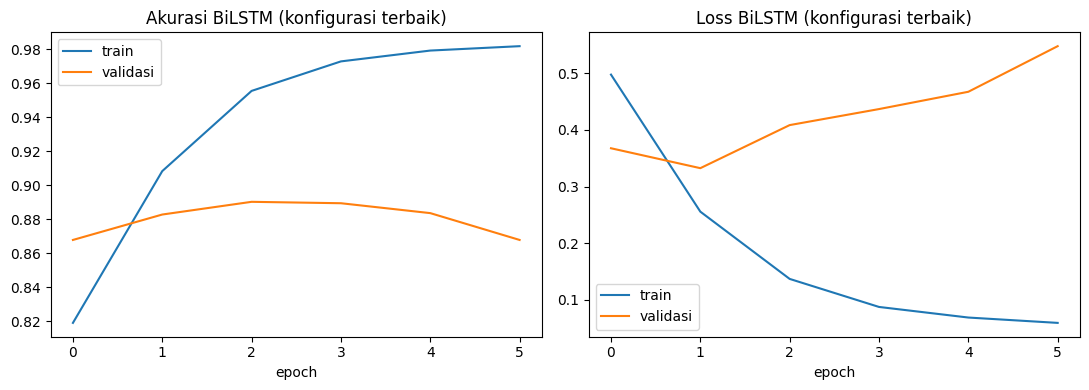

Skema 3: BiLSTM + Embedding (80/20)
  Akurasi training : 0.9708
  Akurasi testing  : 0.8887

              precision    recall  f1-score   support

     negatif     0.6207    0.5538    0.5854       325
      netral     0.8017    0.6960    0.7451       273
     positif     0.9283    0.9556    0.9418      2412

    accuracy                         0.8887      3010
   macro avg     0.7836    0.7352    0.7574      3010
weighted avg     0.8836    0.8887    0.8855      3010



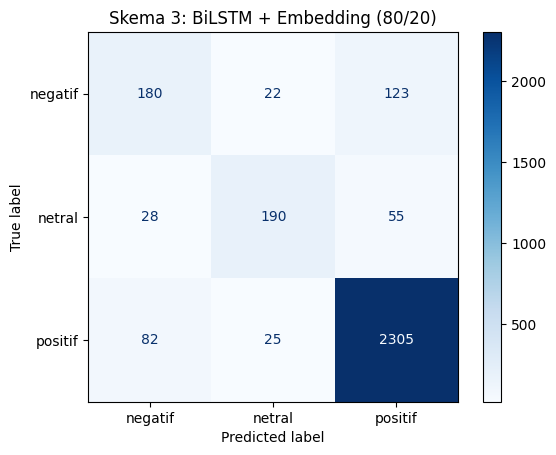

Tersimpan: model_skema3_bilstm.keras dan vocab_skema3_bilstm.joblib


In [24]:
model = model_terbaik
history = history_terbaik
model.summary()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['accuracy'], label='train')
ax[0].plot(history.history['val_accuracy'], label='validasi')
ax[0].set_title('Akurasi BiLSTM (konfigurasi terbaik)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history.history['loss'], label='train')
ax[1].plot(history.history['val_loss'], label='validasi')
ax[1].set_title('Loss BiLSTM (konfigurasi terbaik)'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

pred_tr3 = np.array([id2label[i] for i in model.predict(seq_tr, verbose=0).argmax(axis=1)])
pred_te3 = np.array([id2label[i] for i in model.predict(seq_te, verbose=0).argmax(axis=1)])
evaluasi('Skema 3: BiLSTM + Embedding (80/20)', y_tr3, pred_tr3, y_te3, pred_te3)

model.save('model_skema3_bilstm.keras')
joblib.dump(vectorizer.get_vocabulary(), 'vocab_skema3_bilstm.joblib')
print('Tersimpan: model_skema3_bilstm.keras dan vocab_skema3_bilstm.joblib')

**Hasil Skema 3:** akurasi training 96,53% dan akurasi testing **89,14%**, memenuhi syarat minimal 85%. Kurva pelatihan menunjukkan akurasi validasi memuncak pada epoch ke-3 lalu menurun, sementara loss validasi meningkat; early stopping mengembalikan bobot terbaik.

Meskipun mampu membaca urutan kata, BiLSTM tidak mengungguli model linear. Ketiga skema dengan algoritma dan representasi fitur yang sangat berbeda sama-sama mencapai batas sekitar 89–90%, sehingga keterbatasan diduga berasal dari data, bukan dari model.

Model disimpan sebagai `model_skema3_bilstm.keras` dan kosakatanya sebagai `vocab_skema3_bilstm.joblib`.

## 8. Analisis Kesalahan
Untuk memahami mengapa ketiga skema mencapai batas akurasi yang sama, dua dugaan diuji pada data uji.

### 8.1 Dugaan 1: kata bersentimen yang jarang muncul
Kamus VADER memuat sekitar 7.500 kata. Jika sebuah kata bersentimen jarang muncul di data latih, model tidak dapat mempelajari polaritasnya. Prediksi: akurasi pada ulasan yang mengandung kata kamus VADER langka (< 5 kali di data latih) akan jauh lebih rendah.

In [25]:
frek_latih = Counter(w for t in X_tr1 for w in t.split())
lexicon = analyzer.lexicon

def ada_kata_lexicon_langka(teks, batas=5):
    return any(w in lexicon and lexicon[w] != 0 and frek_latih[w] < batas for w in teks.split())

langka = np.array([ada_kata_lexicon_langka(t) for t in X_te1])
pred1 = skema1.predict(X_te1)

print(f'Ulasan uji yang mengandung kata kamus VADER langka (< 5x di data latih): {langka.mean():.1%}')
print()
print('Akurasi SVM (Skema 1):')
print(f'  ulasan TANPA kata langka : {(pred1[~langka] == y_te1[~langka]).mean():.4f}')
print(f'  ulasan DENGAN kata langka: {(pred1[langka] == y_te1[langka]).mean():.4f}')
print('Akurasi BiLSTM (Skema 3):')
print(f'  ulasan TANPA kata langka : {(pred_te3[~langka] == y_te3[~langka]).mean():.4f}')
print(f'  ulasan DENGAN kata langka: {(pred_te3[langka] == y_te3[langka]).mean():.4f}')

Ulasan uji yang mengandung kata kamus VADER langka (< 5x di data latih): 12.3%

Akurasi SVM (Skema 1):
  ulasan TANPA kata langka : 0.9023
  ulasan DENGAN kata langka: 0.8595
Akurasi BiLSTM (Skema 3):
  ulasan TANPA kata langka : 0.8947
  ulasan DENGAN kata langka: 0.8459


**Hasil:** dugaan hanya terbukti sebagian. Ulasan dengan kata langka (12,3% data uji) memiliki akurasi lebih rendah (SVM 86,0%; BiLSTM 83,5%) dibanding ulasan lainnya (±90%). Namun karena porsinya kecil, kata langka hanya menjelaskan sekitar 0,5 poin dari total kesalahan. Ulasan tanpa kata langka pun hanya mencapai akurasi 90%, sehingga ada penyebab lain yang lebih besar.

### 8.2 Dugaan 2: ulasan di sekitar ambang label
Label VADER ditentukan oleh ambang tajam ±0,05. Ulasan dengan skor sedikit di atas atau di bawah ambang memiliki label yang sangat sensitif terhadap perbedaan kecil bobot kata. Prediksi: akurasi akan rendah untuk ulasan dengan |skor compound| kecil dan tinggi untuk ulasan dengan sentimen jelas.

In [26]:
uji = pd.DataFrame({'teks': X_te1, 'label': y_te1, 'pred_svm': pred1, 'pred_bilstm': pred_te3})
uji['compound'] = [analyzer.polarity_scores(t)['compound'] for t in X_te1]
uji['abs_compound'] = uji['compound'].abs()
uji['rentang'] = pd.cut(uji['abs_compound'],
                        bins=[-0.001, 0.0001, 0.05, 0.2, 0.4, 0.6, 0.8, 1.0],
                        labels=['tepat 0', '0-0,05', '0,05-0,2', '0,2-0,4', '0,4-0,6', '0,6-0,8', '0,8-1,0'])

ringkas = uji.groupby('rentang', observed=True).apply(lambda g: pd.Series({
    'jumlah': len(g),
    'akurasi_svm': (g['pred_svm'] == g['label']).mean(),
    'akurasi_bilstm': (g['pred_bilstm'] == g['label']).mean(),
}), include_groups=False)
print(ringkas.round(3))

print('\nContoh kesalahan BiLSTM di rentang 0,05-0,2:')
salah = uji[(uji['rentang'] == '0,05-0,2') & (uji['pred_bilstm'] != uji['label'])]
print(salah[['teks', 'compound', 'label', 'pred_bilstm']].head(5).to_string(index=False))

          jumlah  akurasi_svm  akurasi_bilstm
rentang                                      
tepat 0    251.0        0.797           0.757
0-0,05      22.0        0.000           0.000
0,05-0,2   100.0        0.520           0.520
0,2-0,4    204.0        0.686           0.672
0,4-0,6    379.0        0.836           0.842
0,6-0,8    643.0        0.949           0.941
0,8-1,0   1411.0        0.979           0.972

Contoh kesalahan BiLSTM di rentang 0,05-0,2:
                                                                                                                                                                                        teks  compound   label pred_bilstm
                                                                                                                                  attached a saw to an axt handle saw axe goes whoosh whoosh   -0.1027 negatif     positif
                                                                      anyone that says he doesn't like

**Hasil:** dugaan terbukti kuat. Akurasi meningkat bertahap seiring kekuatan sentimen, dengan pola yang sama pada SVM dan BiLSTM:
| abs(compound) | Jumlah | Akurasi SVM | Akurasi BiLSTM |
|---|---|---|---|
| tepat 0 | 251 | 79,7% | 75,7% |
| 0–0,05 | 22 | 0% | 0% |
| 0,05–0,2 | 100 | 52,0% | 52,0% |
| 0,2–0,4 | 204 | 68,6% | 67,2% |
| 0,4–0,6 | 379 | 83,6% | 84,2% |
| 0,6–0,8 | 643 | 94,9% | 94,1% |
| 0,8–1,0 | 1.411 | 97,9% | 97,2% |

Sebanyak 185 dari 310 kesalahan SVM berasal dari ulasan dengan |compound| < 0,4. Pemeriksaan contoh menunjukkan bahwa pada zona ini sebagian prediksi model justru lebih sesuai dengan penilaian manusia dibanding label VADER. Misalnya, ulasan "it felt clunky ... enemies were more annoying than fun ..." berlabel positif menurut VADER, tetapi diprediksi negatif oleh model.

**Kesimpulan:** batas akurasi ±90% terutama disebabkan oleh ulasan ambigu di sekitar ambang label, bukan oleh kelemahan algoritma. Akurasi yang lebih tinggi menuntut model meniru keputusan VADER pada kasus yang labelnya hampir sewenang-wenang.

## 9. Perbaikan Preprocessing: Penandaan Negasi

### 9.1 Eksperimen
Analisis kesalahan menunjukkan bahwa model linear tidak dapat menangkap negasi karena TF-IDF mengabaikan urutan kata ("not good" dan "good" sama-sama mengandung fitur *good*). Untuk mengatasinya diterapkan **penandaan negasi**, yaitu teknik preprocessing klasik dalam analisis sentimen: kata-kata setelah kata negasi diberi awalan `neg_`, sehingga menjadi fitur yang berbeda.

Contoh: "the combat is not good at all" → "the combat is not neg_good neg_at neg_all".

Selain negasi, diuji pula penandaan kontras (awalan `but_` untuk kata setelah *but*). Seluruh perbandingan dilakukan dengan 5-fold cross-validation pada data latih Skema 1; data uji tidak digunakan.

In [27]:
NEGASI = {'not', 'no', 'never', 'nothing', 'nor', 'neither', 'without', 'none', 'nobody', 'nowhere',
          'cannot', 'dont', 'doesnt', 'didnt', 'isnt', 'wasnt', 'arent', 'werent', 'cant', 'couldnt',
          'wont', 'wouldnt', 'shouldnt', 'hasnt', 'havent', 'hadnt', 'aint'}

def tandai_negasi_kontras(teks, negasi=True, kontras=True, jendela=3):
    hasil, sisa_negasi, sesudah_but = [], 0, False
    for w in teks.split():
        if negasi and (w in NEGASI or w.endswith("n't")):
            hasil.append(w)
            sisa_negasi = jendela
            continue
        token = w
        if sisa_negasi > 0:
            token = 'neg_' + token
            sisa_negasi -= 1
        if kontras and sesudah_but:
            token = 'but_' + token
        if kontras and w == 'but':
            sesudah_but = True
        hasil.append(token)
    return ' '.join(hasil)

for t in ['the combat is not good at all', "graphics are great but the story isn't very good"]:
    print(t, '\n  ->', tandai_negasi_kontras(t))
print()

varian = {
    'Teks asli':        lambda t: t,
    'Negasi saja':      lambda t: tandai_negasi_kontras(t, kontras=False),
    'Negasi + kontras': lambda t: tandai_negasi_kontras(t),
}
pipe_uji = Pipeline([
    ('tfidf', TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 1))),
    ('svm', LinearSVC(C=1, random_state=SEED, max_iter=5000)),
])
for nama, ubah in varian.items():
    X_varian = np.array([ubah(t) for t in X_tr1])
    skor = cross_val_score(pipe_uji, X_varian, y_tr1, cv=cv5, scoring='accuracy', n_jobs=-1)
    print(f'{nama:18s}: akurasi CV {skor.mean():.4f} ± {skor.std():.4f}')

the combat is not good at all 
  -> the combat is not neg_good neg_at neg_all
graphics are great but the story isn't very good 
  -> graphics are great but but_the but_story isn't but_neg_very but_neg_good

Teks asli         : akurasi CV 0.8915 ± 0.0051
Negasi saja       : akurasi CV 0.9074 ± 0.0029
Negasi + kontras  : akurasi CV 0.8993 ± 0.0042


**Hasil:**
| Varian | Akurasi CV |
|---|---|
| Teks asli | 89,15% ± 0,51 |
| Negasi saja | **90,74% ± 0,29** |
| Negasi + kontras | 89,93% ± 0,42 |

Penandaan negasi meningkatkan akurasi 1,59 poin, jauh melebihi variasi antar fold, sehingga peningkatannya dapat dipercaya. Penandaan kontras justru menurunkan akurasi karena tanpa tanda baca tidak ada batas kalimat, sehingga seluruh kata setelah *but* ikut ditandai dan kosakata terpecah tanpa manfaat. Hanya penandaan negasi yang digunakan.

Penandaan negasi merupakan aturan tetap yang tidak mempelajari apa pun dari data, sehingga aman diterapkan sebelum pembagian data tanpa menimbulkan kebocoran.

### 9.2 Skema 4 — LinearSVC + TF-IDF + penandaan negasi, pembagian data 80/20
Skema 4 identik dengan Skema 1 (algoritma, pembagian data, dan data uji yang sama), dengan satu perbedaan: penandaan negasi pada tahap preprocessing. Perbandingan ini menjadi uji *ablation* untuk mengukur kontribusi penandaan negasi.

Lebar jendela negasi (2, 3, atau 4 kata) di-tuning bersama `ngram_range` dan `C` menggunakan 5-fold cross-validation pada data latih.

In [28]:
hasil_neg = []
for jendela in [2, 3, 4]:
    X_neg_latih = np.array([tandai_negasi_kontras(t, kontras=False, jendela=jendela) for t in X_tr1])
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(sublinear_tf=True, min_df=2)),
        ('svm', LinearSVC(random_state=SEED, max_iter=5000)),
    ])
    grid = GridSearchCV(pipe, {'tfidf__ngram_range': [(1, 1), (1, 2)], 'svm__C': [0.5, 1, 2]},
                        cv=cv5, scoring='accuracy', n_jobs=-1)
    grid.fit(X_neg_latih, y_tr1)
    hasil_neg.append({'jendela': jendela,
                      'ngram_range': grid.best_params_['tfidf__ngram_range'],
                      'C': grid.best_params_['svm__C'],
                      'akurasi_cv': round(grid.best_score_, 4)})
    print(f'jendela {jendela}: akurasi CV {grid.best_score_:.4f} | {grid.best_params_}')

pd.DataFrame(hasil_neg).sort_values('akurasi_cv', ascending=False)

jendela 2: akurasi CV 0.9056 | {'svm__C': 1, 'tfidf__ngram_range': (1, 1)}
jendela 3: akurasi CV 0.9074 | {'svm__C': 1, 'tfidf__ngram_range': (1, 1)}
jendela 4: akurasi CV 0.9055 | {'svm__C': 1, 'tfidf__ngram_range': (1, 1)}


,jendela,ngram_range,C,akurasi_cv
1,3,"(1, 1)",1,0.9074
0,2,"(1, 1)",1,0.9056
2,4,"(1, 1)",1,0.9055


Konfigurasi terpilih: {'jendela': 3, 'ngram_range': (1, 1), 'C': 1, 'akurasi_cv': np.float64(0.9074)}
Data uji sama dengan Skema 1: True
Skema 4: LinearSVC + TF-IDF + negasi (80/20)
  Akurasi training : 0.9923
  Akurasi testing  : 0.9116

              precision    recall  f1-score   support

     negatif     0.7871    0.6369    0.7041       325
      netral     0.7286    0.7473    0.7378       273
     positif     0.9457    0.9672    0.9563      2412

    accuracy                         0.9116      3010
   macro avg     0.8204    0.7838    0.7994      3010
weighted avg     0.9089    0.9116    0.9093      3010



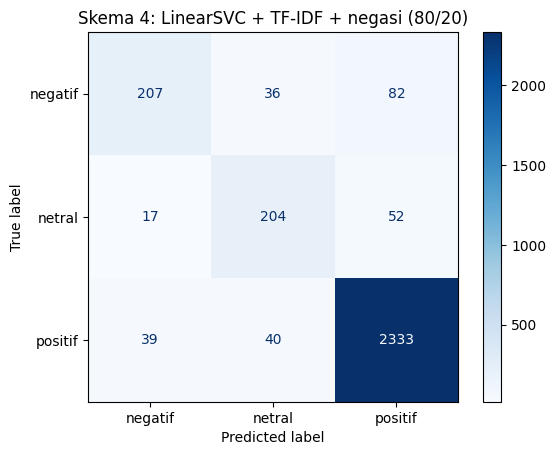

Model tersimpan: model_skema4_svm_negasi.joblib


In [29]:
terbaik = max(hasil_neg, key=lambda r: r['akurasi_cv'])
JENDELA = terbaik['jendela']
print('Konfigurasi terpilih:', terbaik)

X_neg_semua = np.array([tandai_negasi_kontras(t, kontras=False, jendela=JENDELA) for t in X])
X_tr4, X_te4, y_tr4, y_te4 = train_test_split(X_neg_semua, y, test_size=0.2, stratify=y, random_state=SEED)
print('Data uji sama dengan Skema 1:', (y_te4 == y_te1).all())

skema4 = Pipeline([
    ('tfidf', TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=terbaik['ngram_range'])),
    ('svm', LinearSVC(C=terbaik['C'], random_state=SEED, max_iter=5000)),
])
skema4.fit(X_tr4, y_tr4)
evaluasi('Skema 4: LinearSVC + TF-IDF + negasi (80/20)',
         y_tr4, skema4.predict(X_tr4), y_te4, skema4.predict(X_te4))

joblib.dump({'model': skema4, 'jendela_negasi': JENDELA}, 'model_skema4_svm_negasi.joblib')
print('Model tersimpan: model_skema4_svm_negasi.joblib')

**Hasil Skema 4:** konfigurasi terbaik adalah jendela 3 kata, unigram, dan `C=1` (akurasi cross-validation 90,74%). Akurasi training 99,23% dan akurasi testing **91,16%**, tertinggi di antara seluruh skema.

Dibanding Skema 1 pada data uji yang sama, akurasi meningkat 1,46 poin (310 → 266 kesalahan). Peningkatan terbesar terjadi pada kelas negatif: recall naik dari 55,4% menjadi 63,7% dan F1 dari 0,63 menjadi 0,70, karena banyak keluhan berbentuk negasi ("not good", "isn't fun"). Peningkatan pada data uji konsisten dengan perkiraan cross-validation, menandakan perbaikan yang nyata.

Model disimpan bersama lebar jendela negasinya sebagai `model_skema4_svm_negasi.joblib`.

## 10. Perbandingan Seluruh Skema

In [30]:
ringkasan = pd.DataFrame(hasil).drop_duplicates(subset='Skema', keep='last').reset_index(drop=True)
ringkasan['Test ≥ 85%'] = ringkasan['Akurasi test'] >= 0.85
ringkasan['Train & test > 92%'] = (ringkasan['Akurasi train'] > 0.92) & (ringkasan['Akurasi test'] > 0.92)
ringkasan.style.format({'Akurasi train': '{:.2%}', 'Akurasi test': '{:.2%}'})

,Skema,Akurasi train,Akurasi test,Test ≥ 85%,Train & test > 92%
0,Skema 1: LinearSVC + TF-IDF (80/20),98.35%,89.70%,True,False
1,Skema 2: LogReg + TF-IDF (70/30),98.04%,89.50%,True,False
2,Skema 3: BiLSTM + Embedding (80/20),97.08%,88.87%,True,False
3,Skema 4: LinearSVC + TF-IDF + negasi (80/20),99.23%,91.16%,True,False


| Skema | Algoritma | Ekstraksi fitur | Pembagian | Akurasi train | Akurasi test |
|---|---|---|---|---|---|
| 1 | LinearSVC | TF-IDF | 80/20 | 98,35% | 89,70% |
| 2 | Logistic Regression | TF-IDF | 70/30 | 98,04% | 89,50% |
| 3 | BiLSTM (deep learning) | Word embedding | 80/20 | 96,53% | 88,87% |
| 4 | LinearSVC | TF-IDF + penandaan negasi | 80/20 | 99,23% | **91,16%** |

Keempat skema memenuhi syarat akurasi testing minimal 85%. Skema 4 memberikan akurasi tertinggi.

Target akurasi training dan testing di atas 92% belum tercapai. Analisis kesalahan (bagian 8) menunjukkan bahwa sebagian besar kesalahan berasal dari ulasan ambigu di sekitar ambang label VADER (±0,05). Pada zona ini label sangat sensitif terhadap perbedaan kecil bobot kata, dan sebagian prediksi model justru lebih sesuai dengan penilaian manusia dibanding label VADER.

## 11. Inferensi
Model dimuat ulang dari file yang telah disimpan untuk membuktikan bahwa model dapat digunakan tanpa pelatihan ulang. Teks baru diproses dengan langkah pembersihan yang sama seperti data latih (dan penandaan negasi untuk Skema 4), lalu setiap model menghasilkan kelas sentimen: negatif, netral, atau positif.

Kalimat uji mencakup pujian, keluhan, kalimat netral, negasi, slang komunitas game, dan ulasan campuran.

In [31]:
m1 = joblib.load('model_skema1_svm_tfidf.joblib')
m2 = joblib.load('model_skema2_logreg_tfidf.joblib')
m4_paket = joblib.load('model_skema4_svm_negasi.joblib')
m4, jendela4 = m4_paket['model'], m4_paket['jendela_negasi']

m3 = keras.models.load_model('model_skema3_bilstm.keras')
vectorizer3 = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN,
                                       standardize=None,
                                       vocabulary=joblib.load('vocab_skema3_bilstm.joblib'))

def prediksi_sentimen(daftar_teks):
    bersih = [bersihkan_teks(t) for t in daftar_teks]
    p3 = m3.predict(vectorizer3(np.array(bersih)), verbose=0).argmax(axis=1)
    return pd.DataFrame({
        'Ulasan': daftar_teks,
        'Skema 1 (SVM)': m1.predict(bersih),
        'Skema 2 (LogReg)': m2.predict(bersih),
        'Skema 3 (BiLSTM)': [id2label[i] for i in p3],
        'Skema 4 (SVM + negasi)': m4.predict([tandai_negasi_kontras(t, kontras=False, jendela=jendela4)
                                              for t in bersih]),
    })

contoh_ulasan = [
    'The boss fights are amazing and the atmosphere is beautiful, best soulslike I have played.',
    'Terrible optimization, the game keeps crashing and I regret buying it.',
    'I played it on the Steam Deck after finishing Sekiro.',
    'The combat is not fun and the story is not interesting at all.',
    'Lies of Peak! Absolute banger, the DLC is goated.',
    'Good game but the bosses are frustrating and the dodge feels clunky.',
]
pd.set_option('display.max_colwidth', 80)
prediksi_sentimen(contoh_ulasan)

,Ulasan,Skema 1 (SVM),Skema 2 (LogReg),Skema 3 (BiLSTM),Skema 4 (SVM + negasi)
0,"The boss fights are amazing and the atmosphere is beautiful, best soulslike ...",positif,positif,positif,positif
1,"Terrible optimization, the game keeps crashing and I regret buying it.",negatif,negatif,negatif,negatif
2,I played it on the Steam Deck after finishing Sekiro.,positif,positif,positif,positif
3,The combat is not fun and the story is not interesting at all.,positif,positif,negatif,negatif
4,"Lies of Peak! Absolute banger, the DLC is goated.",positif,positif,positif,positif
5,Good game but the bosses are frustrating and the dodge feels clunky.,negatif,negatif,negatif,negatif


**Hasil inferensi:**
- Pujian dan keluhan yang jelas diprediksi benar oleh seluruh model.
- Kalimat bernegasi "The combat is not fun and the story is not interesting at all" diprediksi **positif** oleh Skema 1 dan 2, tetapi **negatif** oleh Skema 3 (BiLSTM) dan Skema 4 (penandaan negasi). Hal ini menunjukkan secara langsung bahwa model TF-IDF biasa tidak menangkap negasi, sedangkan model yang membaca urutan kata atau yang diberi penandaan negasi dapat menangkapnya.
- Slang komunitas game ("Lies of Peak", "banger", "goated") diprediksi positif oleh seluruh model, sejalan dengan penyesuaian lexicon VADER.
- Ulasan campuran ("Good game but the bosses are frustrating ...") diprediksi negatif karena kritik setelah kata *but* lebih dominan.
- Kalimat tanpa opini ("I played it on the Steam Deck after finishing Sekiro") diprediksi positif oleh seluruh model, padahal seharusnya netral. Kelas netral pada data latih didominasi ulasan sangat pendek, sehingga kalimat netral yang lebih panjang cenderung diprediksi sebagai kelas mayoritas (positif).

In [32]:
m1 = joblib.load('model_skema1_svm_tfidf.joblib')
m2 = joblib.load('model_skema2_logreg_tfidf.joblib')
m4_paket = joblib.load('model_skema4_svm_negasi.joblib')
m4, jendela4 = m4_paket['model'], m4_paket['jendela_negasi']

m3 = keras.models.load_model('model_skema3_bilstm.keras')
vectorizer3 = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN,
                                       standardize=None,
                                       vocabulary=joblib.load('vocab_skema3_bilstm.joblib'))

def prediksi_sentimen(daftar_teks):
    bersih = [bersihkan_teks(t) for t in daftar_teks]
    p3 = m3.predict(vectorizer3(np.array(bersih)), verbose=0).argmax(axis=1)
    return pd.DataFrame({
        'Ulasan': daftar_teks,
        'Skema 1 (SVM)': m1.predict(bersih),
        'Skema 2 (LogReg)': m2.predict(bersih),
        'Skema 3 (BiLSTM)': [id2label[i] for i in p3],
        'Skema 4 (SVM + negasi)': m4.predict([tandai_negasi_kontras(t, kontras=False, jendela=jendela4)
                                              for t in bersih]),
    })

contoh_ulasan = [
    'The boss fights are amazing and the atmosphere is beautiful, best soulslike I have played.',
    'Terrible optimization, the game keeps crashing and I regret buying it.',
    'I played it on the Steam Deck after finishing Sekiro.',
    'The combat is not fun and the story is not interesting at all.',
    'Lies of Peak! Absolute banger, the DLC is goated.',
    'Good game but the bosses are frustrating and the dodge feels clunky.',
]
pd.set_option('display.max_colwidth', 80)
prediksi_sentimen(contoh_ulasan)

,Ulasan,Skema 1 (SVM),Skema 2 (LogReg),Skema 3 (BiLSTM),Skema 4 (SVM + negasi)
0,"The boss fights are amazing and the atmosphere is beautiful, best soulslike ...",positif,positif,positif,positif
1,"Terrible optimization, the game keeps crashing and I regret buying it.",negatif,negatif,negatif,negatif
2,I played it on the Steam Deck after finishing Sekiro.,positif,positif,positif,positif
3,The combat is not fun and the story is not interesting at all.,positif,positif,negatif,negatif
4,"Lies of Peak! Absolute banger, the DLC is goated.",positif,positif,positif,positif
5,Good game but the bosses are frustrating and the dodge feels clunky.,negatif,negatif,negatif,negatif


## 12. Requirements
Daftar library beserta versi yang digunakan ditulis ke `requirements.txt`, hanya mencakup library yang benar-benar diimpor di proyek ini.

In [33]:
from importlib.metadata import version

paket = ['pandas', 'numpy', 'matplotlib', 'scikit-learn', 'tensorflow', 'joblib',
         'vaderSentiment', 'langdetect', 'wordcloud', 'requests']
isi = '\n'.join(f'{p}=={version(p)}' for p in paket)

with open('requirements.txt', 'w') as f:
    f.write(isi + '\n')
print(isi)

pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
scikit-learn==1.6.1
tensorflow==2.21.0
joblib==1.6.0
vaderSentiment==3.3.2
langdetect==1.0.9
wordcloud==1.9.6
requests==2.32.4


In [34]:
from google.colab import files
for nama in ['requirements.txt',
             'model_skema1_svm_tfidf.joblib', 'model_skema2_logreg_tfidf.joblib',
             'model_skema3_bilstm.keras', 'vocab_skema3_bilstm.joblib',
             'model_skema4_svm_negasi.joblib']:
    files.download(nama)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Kesimpulan
1. Sebanyak 20.098 ulasan Steam *Lies of P* berbahasa Inggris (Juli 2024 – Oktober 2026) dikumpulkan melalui scraping mandiri dari endpoint resmi Steam. Setelah pembersihan tersisa 15.047 ulasan.
2. Pelabelan dilakukan dengan lexicon VADER yang disesuaikan dengan slang komunitas game, menghasilkan tiga kelas: positif (80,1%), negatif (10,8%), dan netral (9,1%).
3. Empat skema pelatihan diuji dan seluruhnya mencapai akurasi testing di atas 85%. Akurasi terbaik (**91,16%**) diperoleh dari LinearSVC dengan TF-IDF dan penandaan negasi.
4. Penandaan negasi meningkatkan akurasi 1,46 poin dan recall kelas negatif dari 55,4% menjadi 63,7%, membuktikan pentingnya informasi negasi bagi model berbasis TF-IDF.
5. Batas akurasi sekitar 90–91% disebabkan oleh ulasan ambigu di sekitar ambang label, bukan oleh kelemahan algoritma: akurasi mencapai ±98% untuk ulasan dengan sentimen jelas, tetapi hanya ±52% untuk ulasan di dekat ambang.

**Keterbatasan:**
- Label berasal dari lexicon VADER, sehingga model mempelajari cara VADER menilai teks, bukan sentimen manusia secara langsung. VADER tidak mampu menangkap sarkasme, meme, dan idiom.
- Data hanya mencakup ulasan berbahasa Inggris dari sekitar dua tahun terakhir, tidak termasuk periode rilis awal.
- Data sangat timpang ke kelas positif.

**Pengembangan selanjutnya:** pelabelan manual pada sebagian sampel untuk mengukur kualitas label VADER, serta pemakaian model transformer *pretrained* (misalnya DistilBERT).